# Homework assignment #2

**YOUR NAME**


You are free to use any code developed in the class or the textbook.

When your solution contains computer code, please submit the work as a Jupyter notebook. Please write your name near the top of the notebook.

If your solution contains hand-written calculations, it is probably easiest to submit these on paper in class. You can type mathematics using LaTeX expressions between dollar signs (if you know how to do that), but hand written is usually easier and is fine.

All question numbers refer to exercises in the textbook.

## Section 2.1 #1

Hint: here is some code to create a matrix based on a function to be evaluated for each entry (i,j).

**Answers:**

(a) $5$ points are given, hence the maximum necessary degree of this polynomial is $4$.

(b) Interpolating polynomial $p(t)=c_0+c_1 t + c_2 t^2 + c_3 t^3 + c_4 t^4$, corresponding linear system:

$$\left\{\begin{array}{l}
c_0-c_1+c_2-c_3+c_4=0\\
c_0=1\\
c_0+2c_1+4c_2+8c_3+16c_4=0\\
c_0+3c_1+9c_2+27c_3+81c_4=1\\
c_0+4c_1+16c_2+64c_3+256c_4=2\\
\end{array}\right.\qquad
\Leftrightarrow\qquad
\begin{bmatrix}
1&-1&1&-1&1\\
1&0&0&0&0\\
1&2&4&8&16\\
1&3&9&27&81\\
1&4&16&64&256
\end{bmatrix}
\begin{bmatrix}c_0\\c_1\\c_2\\c_3\\c_4\end{bmatrix}=
\begin{bmatrix}0\\1\\0\\1\\2\end{bmatrix}
$$

(c) code

In [206]:
local x, M, y
let x, M, y
    x = [-1, 0, 2, 3, 4]
    M = [ x[i] ^ j for i in 1 : length(x), j in 0:length(x) - 1 ]
    y = [0; 1; 0; 1; 2]

    println(M)

    println("c: ", M \ y)
end

[1 -1 1 -1 1; 1 0 0 0 0; 1 2 4 8 16; 1 3 9 27 81; 1 4 16 64 256]
c: [1.0000000000000004, -0.44999999999999896, -0.8249999999999996, 0.5499999999999998, -0.07499999999999998]


Hence the polynomial is $p(t)=1-0.45t-0.825t^2+0.55t^3-0.075t^4$

## Section 2.1 #3

Hint: use the horner function from the textbook (Function 1.3.2) or Polynomial from the package Polynomials to create and evaluate a polynomial from its coefficients.


In [207]:
local x0, x, p_USA, p_India, p_Poland

x0 = [1990, 2000, 2010, 2020];
x = x0 .- 1990;
p_USA = [252.120, 281.711, 309.011, 331.003];
p_India = [873.278, 1056.576, 1234.281, 1_380.004];
p_Poland = [37.960, 38.557, 38.330, 37.847];

(a) The population of the USA in 2005 is estimated to be 295.84 millions.

In [208]:
M = [ x[i] ^ j for i in 1 : length(x), j in 0:length(x) - 1 ]
c_USA = M \ p_USA

f_USA(x) = sum(c_USA .* (x .^ [0, 1, 2, 3]))

f_USA(2005 - 1990)

295.83593750000006

(b)

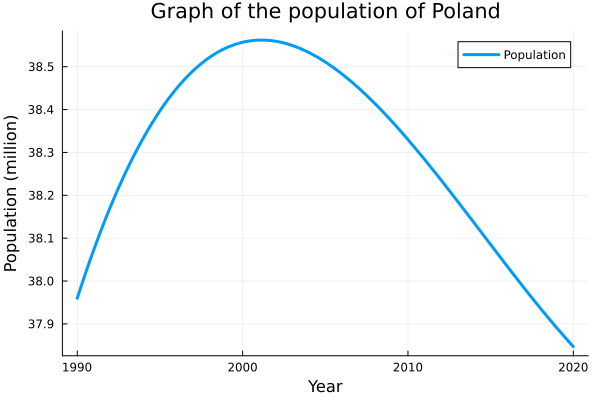

In [209]:
using Plots
using Roots

c_Poland= M \ p_Poland

f_Poland(x) = sum(c_Poland .* ((x - 1990) .^ [0, 1, 2, 3]))

plot(f_Poland, 1990, 2020, 
    title="Graph of the population of Poland", 
    label="Population",
    linewidth=3,
    xlabel="Year",
    ylabel="Population (million)",
    # labelfont=font(14, "Fira Code")
    )


From the graph we can see that there is only one peak within $[1990, 2020]$, likely to be 2000, hence we only need to find the zero point of the first order derivative of the interpolating function `fp_Poland`.

It's 1st order derivative is $p'(t)=c_1+2c_2t+3c_3t^2$.

In [210]:
# derivative of the interpolating function
fp_Poland(x) = sum(c_Poland .* [0, 1, 2, 3] .* ((x - 1990) .^ [0, 0, 1, 2]))
zero = find_zero(fp_Poland, 2000)

println("Peak year: ", zero)
println("Peak population (million): ", f_Poland(round(zero)))

Peak year: 2001.1411616909593
Peak population (million): 38.562008000000006


Therefore the peak locates at year 2001, with maximum population about 38.56 million.

(c) plots:

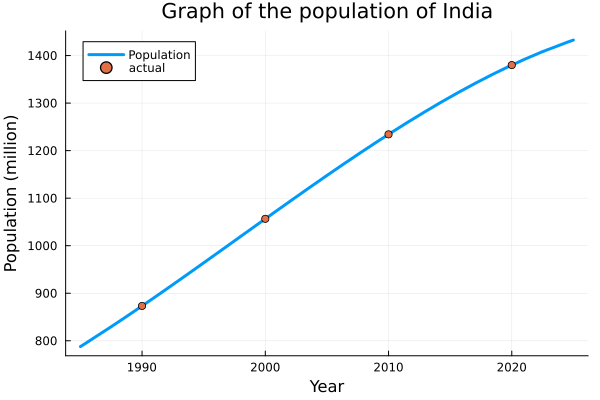

In [211]:
c_India= M \ p_India

f_India(x) = sum(c_India .* ((x - 1990) .^ [0, 1, 2, 3]))

plot(f_India, 1985, 2025, 
    title="Graph of the population of India", 
    label="Population",
    linewidth=3,
    xlabel="Year",
    ylabel="Population (million)"
    # labelfont=font(14, "Fira Code")
    )
scatter!(x0, p_India, label="actual", legend=:topleft)

## Section 2.3 #7

Demo 2.3.6 showed solutions of $Ax=b$, where $A$ and $b$ are computed below as a function of 
$\alpha$ and $\beta$.
Use Function 2.3.5 to solve with $\alpha = 0.1$ and $\beta = 10^i$, $i = 1, \dots, 12$,
tabulating the values of $\beta$ and $|x_1-1|$.
(This kind of behavior is explained in Section 2.8.)

The code below will help you create the table and display it nicely.

In [212]:
# you might want the textbook's backsub function too (Function 2.3.5)
function backsub(U,b)
    n = size(U,1)
    x = zeros(n)
    x[n] = b[n]/U[n,n]
    for i in n-1:-1:1
        s = sum( U[i,j]*x[j] for j in i+1:n )
        x[i] = ( b[i] - s ) / U[i,i]
    end
    return x
end

backsub (generic function with 1 method)

In [213]:
using PrettyTables
using LinearAlgebra

local a, bs, errs
let a, bs, errs
    a = 0.1
    bs = 10 .^ (1 : 12)

    fA(a, b) = diagm(0 => ones(5), 1 => [-1,-1,-1,-1], 3 => [a - b, 0], 4 => [b])
    fb(a) = [a; 0; 0; 0; 1]

    backsub(fA(a, bs[10]), fb(a))

    errs = [abs(backsub(fA(a, b), fb(a))[1] - 1) for b in bs]

    pretty_table([bs errs], crop = :none, header = ["β", "|x₁-1|"])
end

┌──────────┬─────────────┐
│        β │      |x₁-1| │
├──────────┼─────────────┤
│     10.0 │ 4.44089e-16 │
│    100.0 │ 5.77316e-15 │
│   1000.0 │ 2.27596e-14 │
│  10000.0 │  3.6382e-13 │
│ 100000.0 │ 5.82079e-12 │
│    1.0e6 │ 2.32832e-11 │
│    1.0e7 │ 3.72529e-10 │
│    1.0e8 │  5.96046e-9 │
│    1.0e9 │  2.38419e-8 │
│   1.0e10 │   3.8147e-7 │
│   1.0e11 │  6.10352e-6 │
│   1.0e12 │  2.44141e-5 │
└──────────┴─────────────┘


As $\alpha$ increases exponentially, the error of the solution $x$ increases.

## Section 2.4 #6

The `det` function is in LinearAlgebra. You may want Function 2.4.6 from the book to help too.

The function `diag` can be used to extract the diagonal elements of a matrix into a vector. The function `prod` is like `sum`, i.e., instead of adding the entries of a vector, it computes the products of the entries.

**Answer:**

(a) If $A=LU$, by the definition and theorems of determinant, 
$$|L|=\prod_{i=1}^n L_{ii}=1,\quad |U|=\prod_{i=1}^n U_{ii}, \quad |A|=|LU|=|L||U|=\prod_{i=1}^n U_{ii}$$

(b)

In [214]:
function lufact(A)
    n = size(A,1)
    L = diagm(ones(n))   # ones on main diagonal, zeros elsewhere
    U = zeros(n,n)
    Aₖ = float(copy(A))

    # Reduction by outer products
    for k in 1:n-1
        U[k,:] = Aₖ[k,:]
        L[:,k] = Aₖ[:,k]/U[k,k]
        Aₖ -= L[:,k]*U[k,:]'
    end
    U[n,n] = Aₖ[n,n]
    return LowerTriangular(L),UpperTriangular(U)
end

lufact (generic function with 1 method)

In [215]:
function determinant(A)
    _, U = lufact(A)
    return prod(diag(U))
end

determinant (generic function with 1 method)

In [216]:
local A1, A2
let A1, A2

   A1 = [              
         2  4  2   2  4;  #=
      =# 9  5  9   8  7;  #=
      =# 9  3  10  2  2;  #=
      =# 1  2  10  7  8;  #=
      =# 4  3  3   8  6   #
   ];

   A2 = [                 #=
      =#  1  -2  -2  1 -4;  #=
      =# -1  -3   1  5  3;  #=
      =#  3  -2   0  5 -3;  #=
      =#  0  -1  -2 -3 -3;  #=
      =# -2  -1  -4 -5 -4   #
   ];

   println("A1: det: ", det(A1))
   println("    our result: ", determinant(A1))
   println("    error: ", abs(determinant(A1) - det(A1)))

   println("A2: det: ", det(A2))
   println("    our result: ", determinant(A2))
   println("    error: ", abs(determinant(A2) - det(A2)))

end

A1: det: 281.9999999999995


    our result: 282.0000000000009
    error: 1.4210854715202004e-12
A2: det: 2.000000000000068
    our result: 1.999999999999907
    error: 1.609823385706477e-13


As we can see, the absolute error (also relative error since their determinants $> 1$) is extremely small.

## Section 2.5 #8


The UpperTriangular and LowerTriangular matrix types cause specialized algorithms to be invoked by 
the backslash. Define




In [217]:
using LinearAlgebra

A = rand(1000, 1000)
B = tril(A)
C = LowerTriangular(B)
b = rand(1000);


Using `@elapsed` with the backslash solver, time how long it takes to solve the linear system $Ax=b$
100 times; then, do the same for matrices $B$ and $C$. Is the timing for $B$ closer to $A$ or to $C$? 
(Hint: Remember to make one timing run without recording results, so that compilation time is not counted.)

As a bonus, check the time if you use the LU factored form of A.

Hint: this determines the length of time to compute sine of 10 million Normally-distributed random numbers. (About 0.4 s on my computer.) The `_` is a digits separator used to help humans read numbers with many digits.

In [218]:
println("Using backslash: ")
println(" A: ", @elapsed (for i in 1 : 100; 
    A \ b;
end))
println(" B: ", @elapsed (for i in 1 : 100; 
    B \ b;
end))
println(" C: ", @elapsed (for i in 1 : 100; 
    C \ b;
end))

Using backslash: 


 A: 2.2112757
 B: 0.041298


 C: 0.0092961


The timing for $B$ is closer to $C$ rather than $B$, this is probably because that $B, C$ are all triangular matrices, and there exist some specified methods for such matrices.

In [219]:
println(" A with LU decomposition: ", @elapsed (for i in 1 : 100; 
    L, U = lu(A);
    y = L \ b;
    U \ y
end))

L = nothing; U = nothing;
println(" A with LU pre-decomposition: ", @elapsed (for i in 1 : 100; 
    if (i == 1)
        L, U = lu(A);
    end
    y = L \ b;
    U \ y
end))

 A with LU decomposition: 3.2957766
 A with LU pre-decomposition: 0.2132572


Solving time increased by $0.4$ s if we decompose $A$ to $L, U$ every time then solve.

But if we decompose it once, then solve the equation for $100$ times reusing $L, U$, the time decreases hugely to $0.13$ s.

## Section 2.9 #5

The Tridiagonal matrix type invokes a specialized algorithm for solving a linear system.

(a) Set n=1000 and t=0. In a loop that runs 50 times, generate a linear system via
    

In [220]:
n1 = 1000
A1 = triu( tril(rand(n,n),1), -1)
b1 = ones(n);

ts1 = [(@elapsed (for i in 1 : t; 
A1 \ b1;
end)) for t in range(0, 50)]
println("Final value of t: ", ts1[end])

Final value of t: 1.1899208


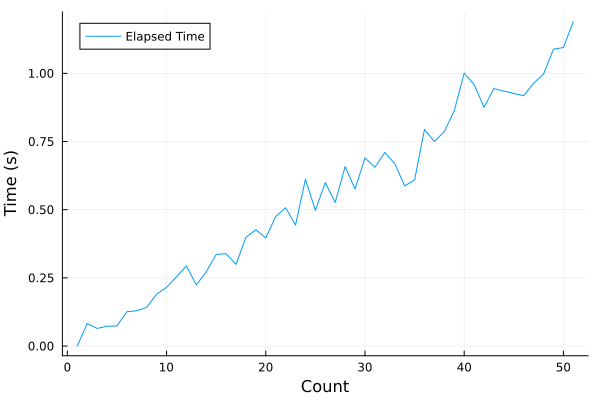

In [221]:
plot(ts1, label="Elapsed Time", xlabel="Count", ylabel="Time (s)")


Using @elapsed, increment t by the time it takes to perform A\b. Print out the final value of t.

(b) Repeat the experiment of part (a), but generate the matrix via
`A = Tridiagonal(rand(n,n))`
What is the ratio of running times for part (a) and (b)?


In [222]:
n2 = 1000
A2 = Tridiagonal(rand(n2, n2))
b2 = ones(n);

ts2 = [(@elapsed (for i in 1 : t; 
A2 \ b2;
end)) for t in range(0, 50)]
println("Final value of t: ", ts2[end])

Final value of t: 0.0013423


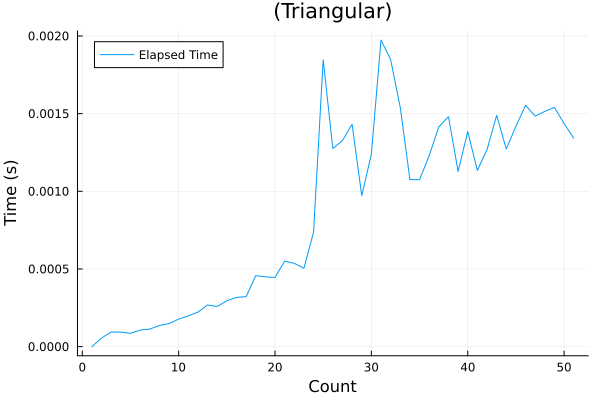

In [223]:
plot(ts2, label="Elapsed Time", xlabel="Count", ylabel="Time (s)", title="(Triangular)")

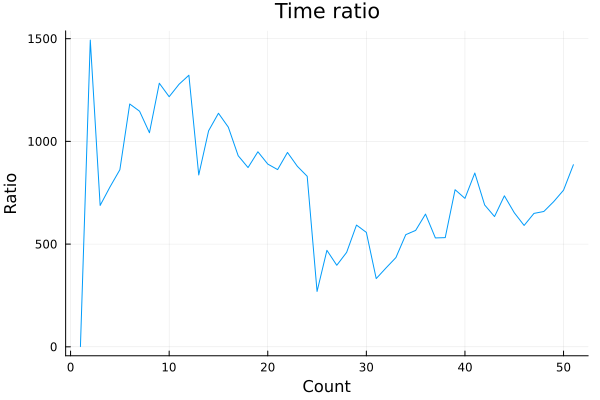

In [224]:
plot(ts1 ./ ts2, label=nothing, xlabel="Count", ylabel="Ratio", title="Time ratio")

In [225]:
sum((ts1 ./ ts2)[5:end]) / (length(ts1) - 5 + 1)

778.8295739569452

From the graph, we can notice that from count=5, the ratio became relatively stable, so we discarded indices 0~4, and calculated the average ratio, it's about $646$. 

(c) Now perform the experiment of part (b) for $n = 1000 + 200k$, $k = 0, \dots, 15$, 
keeping the total time for each value of $n$ in a vector. Plot running time as a function of $n$ on 
a log-log scale. Is the time most like $O(n)$, $O(n^2)$, or $O(n^3)$? 
(If the answer is unclear, try increasing the number of solves per value of to 100 or more.)

In [226]:
ns = 1000 .+ 200 .* (0:15)

ts3 = [0]
for n in ns;
    C = Tridiagonal(rand(n, n))
    b3 = ones(n)
    timi = (@elapsed (for i in 1 : 10000; 
                C \ b3;
            end))
    ts3 = [ts3 timi];
end
ts3 = ts3[2:end];

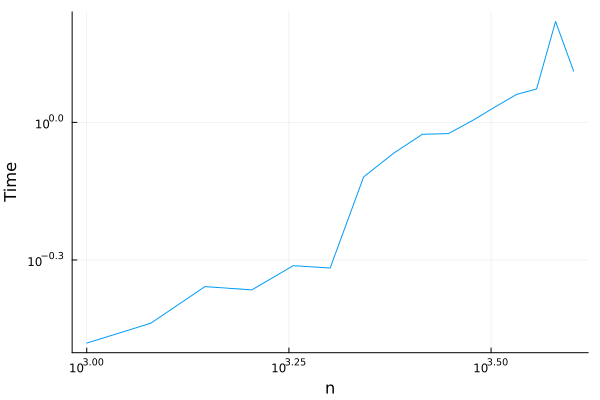

In [227]:
plot(ns, ts3, xaxis=:log, yaxis=:log,
    xlabel="n", ylabel="Time", label=nothing
)

The graph is nearly a straight line, hence the time complexity is most likely to be $O(n)$.

## Section 3.1 #2

Here are counts of the U.S. population in millions from the census performed every ten years, beginning with 1790 and ending with 2010.


In [228]:
usa_pop = [3.929, 5.308, 7.240, 9.638, 12.87, 17.07, 23.19, 31.44, 39.82, 50.19, 62.95, 76.21,
92.22, 106.0, 122.8, 132.2, 150.7, 179.3, 203.3, 226.5, 248.7, 281.4, 308.7];


(a) Find a best-fitting cubic polynomial for the data. Plot the data as points superimposed on a (smooth) graph of the cubic over the full range of time. Label the axes. What does the fit predict for the population in the years 2000, 2010, and 2020?

Predition: 
   2000: 279.1552670112495 million   Real: 281.4 million
   2010: 308.53434046822736 million   Real: 308.7 million
   2020: 339.6777617165442 million   Real (From statistics bureau): 3.295 million

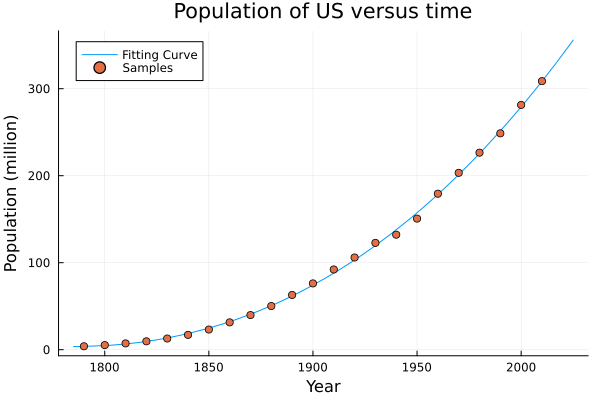

In [229]:
years = 1790:10:2010
ts = [i - 1 for i in range(1, length(years))];
A = [[t .^ i * 1.0 for t in ts] for i in range(0,3)]
A = reshape(collect(Iterators.flatten(A)), 23, 4)

cs = A \ usa_pop

p(x) = sum(cs .* (((x - 1790) / 10) .^ [0, 1, 2, 3]))

println("Predition: ")
println("   2000: ", p(2000), " million   Real: ", usa_pop[end-1], " million")
println("   2010: ", p(2010), " million   Real: ", usa_pop[end], " million")
println("   2020: ", p(2020), " million   Real (From statistics bureau): 3.295 million")

plot(p, 1785, 2025, xlabel="Year", ylabel="Population (million)",
    title="Population of US versus time",
    label="Fitting Curve"
    )
scatter!(years, usa_pop, label="Samples")


(b) Look up the actual U.S. population in 2000, 2010, and 2020 and compare to the predictions of part (a).


| Year | Prediction (million) | Real (million) |
|:----:|:----------:|:------------:|
| 2000 | 279.1552670112495 | 281.4 |
| 2010 | 308.53434046822736 | 308.7 |
| 2020 | 339.6777617165442 | 329.5 | 

From the table, we can note that the predition for years 2000 and 2010 are sufficiently close to the real number (relative error < 1%>), this partly due to that we included these 2 points when calculating the fitting curve.

For year 2022, the predition is still precise (relative < 3%), but the error goes larger.

So we can roughly conclude that the population increses cubicly with respect to the time.

## Section 3.1 #6

One series for finding $\pi$ is

$$\frac{\pi}{2} = 1 + \frac{1}{3} + \frac{1\cdot 2}{3\cdot 5} + \frac{1\cdot 2\cdot 3}{3\cdot 5\cdot 7} + \dots$$
 
Define $s_k$ to be the sum of the first $k$ terms on the right-hand side, and let 
$e_k = |s_k - \pi/2|$.

(a) Calculate $e_k$ for $k=1, \dots, 20$, and plot the sequence on a log-linear scale.

In [230]:
ks = 1:20

cur = 1
ss = [cur]
for k in ks[2:end];
    cur *= (k - 1) / (2 * k - 1)
    ss = [ss ss[end]+cur]
end
ss = ss[:]

es = [abs(s - pi / 2) for s in ss]

20-element Vector{Float64}:
 0.5707963267948966
 0.2374629934615633
 0.10412966012823
 0.04698680298537283
 0.021589977588547526
 0.010045966044536003
 0.004717960716530634
 0.0022315582301282166
 0.0010614864718212491
 0.0005072419547285101
 0.00024331599420812644
 0.00011709053482888976
 5.650231432685615e-5
 2.7330208159259683e-5
 1.3247122423232227e-5
 6.432726099347974e-6
 3.1287763664344936e-6
 1.5240007820160884e-6
 7.432991462330563e-7
 3.6295732375180023e-7

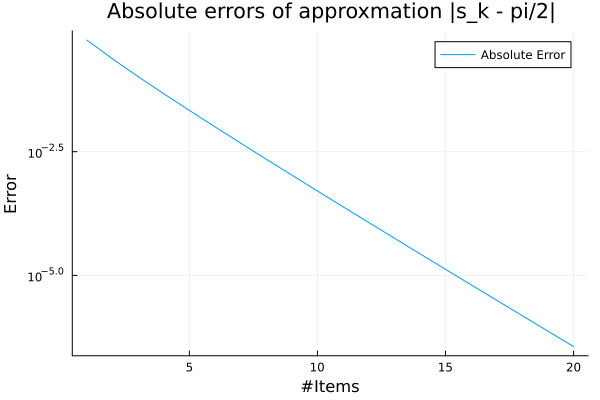

In [231]:
plot(es, yaxis=:log, label="Absolute Error", ylabel="Error", xlabel="#Items",
    title="Absolute errors of approxmation |s_k - pi/2|")

(b) Determine $a$ and $b$ in a least-squares fit $e_k \approx a\cdot b^k$, 
and superimpose the fit on the plot from part (a).

Hints: 

* It's easy to make unnecessary errors in the terms of this series as $k$ gets large (about 20). Be careful how you calculate the terms in the sum.
* Use `yaxis = :log` to transform the axis and keep pretty labels.

a: 0.9371482082402564    b: 0.47527526723108526


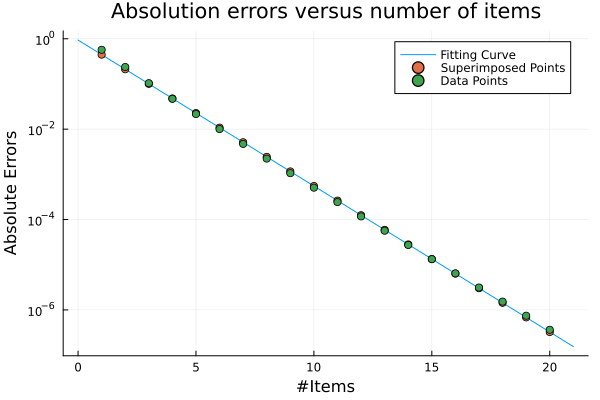

In [232]:
using Plots

A = [ones(length(ks)) ks]

cs = A \ log.(es)
a = exp(cs[1]); b = exp(cs[2])

ys = [a * b ^ k for k in ks]

ekf(k) = a * b ^ k

println("a: ", a, "    b: ", b)

plot(ekf, 0, 21, yaxis=:log, 
    xlabel="#Items", ylabel="Absolute Errors",
    label="Fitting Curve", title="Absolution errors versus number of items")
scatter!(ks, ys, label="Superimposed Points")
scatter!(ks, es, label="Data Points")
